# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [84]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

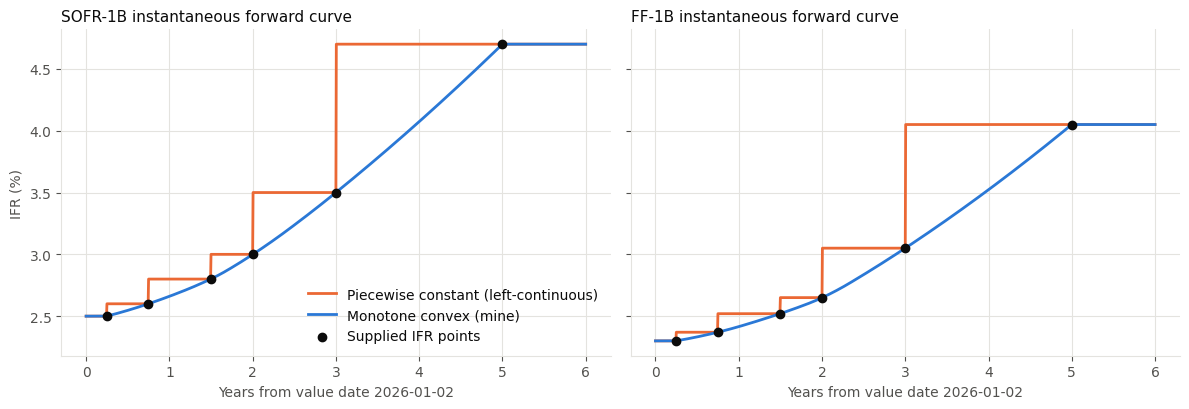

SOFR-1B: hits nodes = True, monotone = True, convex = True
FF-1B: hits nodes = True, monotone = True, convex = True
One-node funding curve is constant: True


In [85]:
# TODO

import numpy as np
import matplotlib.pyplot as plt

VALUE_DATE = "2026-01-02"
INDICES = ("SOFR-1B", "FF-1B")


def make_model(scheme):
    """Yield-curve model from the shared IFR inputs, using the given interpolation scheme."""
    build_list = []
    for kind, inputs in curve_inputs:
        settings = dict(inputs)
        settings["INTERPOLATION METHOD"] = scheme
        settings["EXTRAPOLATION METHOD"] = "FLAT"
        build_list.append(qfCreateBuildMethod(kind, settings))
    collection = qfCreateModelBuildMethodCollection(build_list)
    return qfCreateModel(VALUE_DATE, "YIELD_CURVE", data_collection, collection)


def interpolator(model, index):
    return model.retrieve_model_component(index).state_data_interpolator


def node_data(model, index):
    t_nodes, f_nodes = model.retrieve_model_component(index).state_data[:2]
    return np.asarray(t_nodes), np.asarray(f_nodes)


def evaluate(curve, xs):
    return np.array([curve.interpolate(x) for x in xs])


models = {
    "step": make_model("PIECEWISE_CONSTANT_LEFT_CONTINUOUS"),
    "smooth": make_model("MONOTONE_CONVEX"),
}

# ---------------------------------------------------------------- plot
palette = {"text": "#0b0b0b", "axis": "#52514e", "grid": "#e4e3df",
           "smooth": "#2a78d6", "step": "#eb6834"}
labels = {"step": "Piecewise constant (left-continuous)",
          "smooth": "Monotone convex (mine)"}
t_plot = np.linspace(0.0, 6.0, 1201)

fig, panels = plt.subplots(ncols=2, figsize=(12, 4.2), sharey=True)

for panel, index in zip(panels, INDICES):
    for key in ("step", "smooth"):
        rates = 100 * evaluate(interpolator(models[key], index), t_plot)
        panel.plot(t_plot, rates, lw=2, color=palette[key], label=labels[key])

    t_nodes, f_nodes = node_data(models["smooth"], index)
    panel.scatter(t_nodes, 100 * f_nodes, s=36, zorder=3,
                  color=palette["text"], label="Supplied IFR points")

    panel.set_title(f"{index} instantaneous forward curve",
                    loc="left", fontsize=11, color=palette["text"])
    panel.set_xlabel(f"Years from value date {VALUE_DATE}", color=palette["axis"])
    panel.grid(True, lw=0.8, color=palette["grid"])
    panel.tick_params(colors=palette["axis"])
    panel.spines[["top", "right"]].set_visible(False)
    panel.spines[["left", "bottom"]].set_color(palette["grid"])

panels[0].set_ylabel("IFR (%)", color=palette["axis"])
panels[0].legend(loc="lower right", frameon=False, labelcolor=palette["text"])
fig.tight_layout()
plt.show()

# ---------------------------------------------------------------- shape check
# On [t_0, t_N]: non-negative first differences -> monotone increasing,
#                non-negative second differences -> convex.
def shape_report(model, index, n=20001):
    curve = interpolator(model, index)
    t_nodes, f_nodes = node_data(model, index)
    dense = evaluate(curve, np.linspace(t_nodes[0], t_nodes[-1], n))
    return {
        "hits nodes": np.allclose(evaluate(curve, t_nodes), f_nodes, atol=1e-15),
        "monotone": np.diff(dense).min() >= -1e-15,
        "convex": np.diff(dense, n=2).min() >= -1e-12,
    }


for index in INDICES:
    report = shape_report(models["smooth"], index)
    print(index + ": " + ", ".join(f"{k} = {v}" for k, v in report.items()))

funding = evaluate(interpolator(models["smooth"], "SOFR-1B-FLAT"), [0.0, 1.0, 3.0, 10.0])
print("One-node funding curve is constant:", np.ptp(funding) < 1e-15)

### Approach: monotone, convex C¹ quadratic spline for nodal forward rates (adapted from Hagan–West)

**Starting point.** Hagan and West's monotone convex scheme is built for *discrete* forwards. Each input is an average rate over an interval, and the curve only has to match those averages. Here each input is the *instantaneous* forward at a node, and the curve must pass through it exactly. So I keep their central device and rebuild it for point data. That device is a quadratic on each interval, plus an extra breakpoint inside the interval when one quadratic can't give the right shape (their $\eta$ and region (iv)).

**Building the curve.** Every piece on $[t_0, t_N]$ is a quadratic, so $f'$ is piecewise linear. It is set up in three steps.

1. **Node slopes.** Define the secants $s_i = (f_i - f_{i-1})/(t_i - t_{i-1})$. At an interior node, if $s_i$ and $s_{i+1}$ share a sign, set $d_i = 2s_i s_{i+1}/(s_i + s_{i+1})$, their harmonic mean. If they don't, set $d_i = 0$. At the two ends, $d_0 = 2s_1 - d_1$ and $d_N = 2s_N - d_{N-1}$.
2. **Interior breakpoint.** Given $d_{i-1}$ and $d_i$, insert a breakpoint $\xi$ a fraction $\lambda$ of the way through the interval. For the curve to hit $f_i$ exactly, the slope there must be $D = 2s_i - \lambda d_{i-1} - (1-\lambda)d_i$. Let $\alpha = s_i - d_{i-1}$ and $\beta = d_i - s_i$. If $d_{i-1} \le s_i \le d_i$, any $\lambda \in \left[\frac{\beta-\alpha}{\alpha+\beta}, \frac{2\beta}{\alpha+\beta}\right]$ puts $D$ between $d_{i-1}$ and $d_i$. The slope then rises steadily across the interval, so the piece is convex. I use the midpoint of this range.
3. **Integration.** Each piece is quadratic, so $\int f$, and hence the discount factor, is an exact cubic in closed form.

**Monotonicity.** A harmonic mean of two same-signed numbers lies between them and never exceeds twice the smaller one. Each node slope therefore has the same sign as its neighbouring secants and lies in $[0, 2s_i]$. $D$ stays in that range too, so $f'$ keeps one sign within each interval. The curve can't overshoot either endpoint value, which rules out artificial bumps and negative rates from positive inputs.

**Convexity.** Convex data has increasing secants. Each interior $d_i$ then lies strictly between $s_i$ and $s_{i+1}$, so every interval falls under the convex case in step 2. $f'$ is continuous at the nodes (the curve is $C^1$) and never decreases. That makes the curve convex over the whole node range, not just on each piece. The SOFR and Fed Funds inputs both have increasing secants, so both fitted curves are monotone increasing and convex, as the check above shows.

**When not every property can hold.** Requirements are ranked:

- Continuity and exact interpolation of the nodes always hold.
- Monotonicity holds on every interval.
- Convexity is dropped only where the data itself isn't convex.

Where the secants reverse direction (a hump or an S-shape), the breakpoint goes at the interval midpoint and the curve stays monotone between the two nodes. When exactly collinear points sit next to curved ones, no $C^1$ convex curve exists. In that case I keep convexity and let the slope jump up at that node.

**Beyond the nodes.** The curve is extended flat at $f_0$ and $f_N$, matching the piecewise-constant interpolator. A curve with a single node, such as the funding spread, is just a constant.

In [86]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [87]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3262.2998870220526
Student minus PCP: 354.0132477840889


In [88]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513069761


In [89]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12850.155650356202
Student minus PCP: 6627.638137286442


In [90]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181775


In [91]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7627.726113149314
Student minus PCP: -723.622795032461


In [92]:

overview = pd.DataFrame({
    "Product": ["FRA", "RFR swap", "Overnight basis swap"],
    "PCP PV": [fra_pcp_pv, swap_pcp_pv, basis_pcp_pv],
    "Monotone convex PV": [fra_student_pv, swap_student_pv, basis_student_pv],
})
overview["Difference"] = overview["Monotone convex PV"] - overview["PCP PV"]
overview.round(2)

,Product,PCP PV,Monotone convex PV,Difference
0,FRA,2908.29,3262.30,354.01
1,RFR swap,6222.52,12850.16,6627.64
2,Overnight basis swap,8351.35,7627.73,-723.62


###  PVs difference Reason 

**Root cause.** The left-continuous piecewise-constant curve assigns each interval $(t_{i-1}, t_i]$ the value at its *right* node. Both curves slope upward, so the right node is the highest point on the interval, and every forward between nodes is biased upward. My curve moves smoothly from $f_{i-1}$ to $f_i$. It matches the step curve at the nodes and lies *below* it in between. The funding spread is one constant node in both methods, so all three PV differences come from the SOFR and Fed Funds curves. Discounting also uses SOFR (SOFR-1B-FLAT), so a lower SOFR curve gives higher discount factors as well.

- **FRA (receive 3.2% fixed on 6M SOFR, May–Nov 2026): +354.** Most of the accrual period falls between the 0.25Y and 0.75Y nodes. The step curve applies the 2.6% right-node value across all of it, and its final month already uses the next node's 2.8%. The projected term rate drops from 2.618% to 2.548%, roughly 7bp. For the fixed receiver, the gain is about $N \times \tau \times 7\text{bp} \times D \approx 1{,}000{,}000 \times 0.511 \times 0.0007 \times 0.978 \approx 350$.
- **3Y RFR swap (receive 3.4% fixed): +6,628.** This is the biggest difference. Projected annual rates go from 2.70%, 3.08% and 3.81% to 2.60%, 2.90% and 3.37%. The third year crosses the 3Y node. Right after it, the step curve jumps to the 4.7% five-year value, while my curve rises gradually. The floating leg's PV falls by about 6,290. The fixed leg picks up about 340 from higher discount factors.
- **2Y basis swap (receive SOFR + 10bp, pay Fed Funds): −724.** This value depends on the SOFR minus Fed Funds gap. On the step curve, that gap jumps between node values (22.7, 27.8, 34.8 and 44.6bp) and always takes the wider right-node spread. My curves are smooth, so the gap widens gradually from 21bp to 39bp and is smaller on average. A narrower gap is worth less to the SOFR receiver. The 10bp spread leg depends only on discounting and barely moves (+3).

**Takeaway.** On a rising curve, piecewise-constant forwards are a rough approximation that consistently overstates the forward rate. The error grows with the slope of the curve and the spacing between nodes. A smooth, shape-preserving curve removes this bias and still passes through every input point.